#### **Setup & Data Loading**

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Styling
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (12, 6)

# Load datasets
DATA_PATH = "../data/raw"
sales_lines = pd.read_csv(f"{DATA_PATH}/d365_sales_lines.csv")
item_master = pd.read_csv(f"{DATA_PATH}/d365_item_master.csv")

print(f"Loaded {len(sales_lines)} sales order lines for OTIF analysis.")
sales_lines.head(3)

Loaded 1000 sales order lines for OTIF analysis.


,Document_No_,Posting_Date,Item_No_,Sales_Channel,Destination,Location_Code,Origin_Location,Carrier_Code,Quantity_Ordered,Quantity_Shipped,Promised_Delivery_Date,Actual_Delivery_Date,Delay_Days,OTIF_OnTime,OTIF_InFull,OTIF_Compliant,Delay_Root_Cause,Unit_Price_AED,Line_Amount_AED
0,SO-DXB-30001,2025-10-02,SKU-SPO-1020,B2B Wholesale,Dubai Mall Flagship,DXB-WH-01 (Jebel Ali),Milan Malpensa (MXP),DHL Express,166,166,2025-10-07,2025-10-07,0,True,True,True,On-Time & In-Full,5699.20,946067.20
1,SO-DXB-30002,2025-07-22,SKU-SPO-1143,D2C E-Commerce,D2C UAE Delivery,DXB-WH-01 (Jebel Ali),Florence Peretola (FLR),DHL Express,2,1,2025-07-27,2025-07-27,0,True,False,False,Carrier Transit SLA Breach (GCC Corridor),4974.13,4974.13
2,SO-DXB-30003,2025-08-12,SKU-LUX-1027,Retail Boutique,Dubai Mall Flagship,DXB-WH-01 (Jebel Ali),London Heathrow (LHR),DHL Express,8,8,2025-08-17,2025-08-17,0,True,True,True,On-Time & In-Full,1612.25,12898.00


#### **Global OTIF Performance Calculation**

In [2]:
# Calculate core OTIF percentages
total_orders = len(sales_lines)
ontime_count = sales_lines['OTIF_OnTime'].sum()
infull_count = sales_lines['OTIF_InFull'].sum()
compliant_count = sales_lines['OTIF_Compliant'].sum()

ontime_rate = (ontime_count / total_orders) * 100
infull_rate = (infull_count / total_orders) * 100
otif_rate = (compliant_count / total_orders) * 100

print("==========================================")
print("       SPORTLUX GLOBAL OTIF SCORECARD     ")
print("==========================================")
print(f"Total Orders Evaluated : {total_orders}")
print(f"On-Time Delivery Rate  : {ontime_rate:.2f}%")
print(f"In-Full Delivery Rate  : {infull_rate:.2f}%")
print(f"Full OTIF Compliance   : {otif_rate:.2f}%")
print("==========================================")

       SPORTLUX GLOBAL OTIF SCORECARD     
Total Orders Evaluated : 1000
On-Time Delivery Rate  : 69.60%
In-Full Delivery Rate  : 90.50%
Full OTIF Compliance   : 63.00%


#### **OTIF Breakdown by Sales Channel**

In [3]:
# Group by sales channel
channel_otif = sales_lines.groupby('Sales_Channel').agg(
    Total_Orders=('Document_No_', 'count'),
    On_Time_Rate=('OTIF_OnTime', lambda x: (x.sum() / len(x)) * 100),
    In_Full_Rate=('OTIF_InFull', lambda x: (x.sum() / len(x)) * 100),
    Overall_OTIF=('OTIF_Compliant', lambda x: (x.sum() / len(x)) * 100),
    Avg_Delay_Days=('Delay_Days', 'mean')
).round(2).reset_index()

print("-- OTIF Performance by Sales Channel --")
display(channel_otif)

-- OTIF Performance by Sales Channel --


,Sales_Channel,Total_Orders,On_Time_Rate,In_Full_Rate,Overall_OTIF,Avg_Delay_Days
0,B2B Wholesale,347,69.45,91.93,63.69,0.76
1,D2C E-Commerce,332,71.08,90.66,64.76,0.56
2,Retail Boutique,321,68.22,88.79,60.44,0.71


#### **Root-Cause Attribution Visualization**

C:\Users\tohiba\AppData\Local\Temp\ipykernel_11000\1606007934.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(


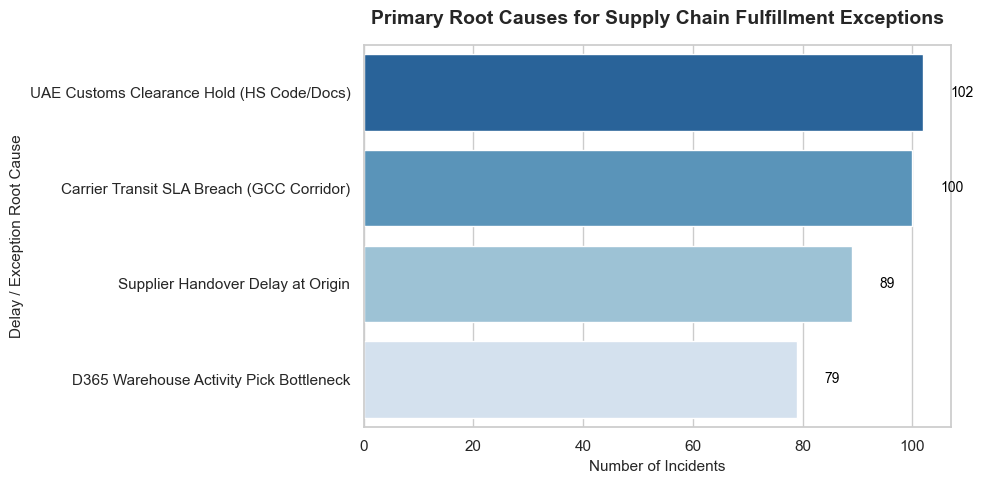

In [4]:
# Filter for delayed or short-shipped orders
exceptions_df = sales_lines[sales_lines['Delay_Root_Cause'] != 'On-Time & In-Full']

# Count root causes
root_cause_counts = exceptions_df['Delay_Root_Cause'].value_counts().reset_index()
root_cause_counts.columns = ['Root_Cause', 'Incident_Count']

# Plotting
plt.figure(figsize=(10, 5))
ax = sns.barplot(
    data=root_cause_counts, 
    x='Incident_Count', 
    y='Root_Cause', 
    palette='Blues_r'
)
plt.title('Primary Root Causes for Supply Chain Fulfillment Exceptions', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Number of Incidents', fontsize=11)
plt.ylabel('Delay / Exception Root Cause', fontsize=11)

for p in ax.patches:
    ax.annotate(f"{int(p.get_width())}", 
                (p.get_width() + 5, p.get_y() + p.get_height() / 2.), 
                ha='left', va='center', fontsize=10, color='black')

plt.tight_layout()
plt.show()